# `pp.banksy_matrix` vs `banksy_py`

Astrolabe's BANKSY feature augmentation (Singhal et al. 2024, *Nature Genetics*) is a from-scratch reimplementation rather than a wrapper around the official `banksy_py` package (installed here as `banksy-py` on PyPI, a maintained fork of `prabhakarlab/Banksy_py`), keeping astrolabe free of its extra dependencies.

This notebook compares the **final λ-weighted concatenated matrices** — `banksy_py`'s `banksy_dict['scaled_gaussian'][λ]['adata'].X` (which z-scores each block internally via `concatenate_all`) against astrolabe's `obsm['X_banksy']` (which now also z-scores each block before applying the √-weights), at the same λ with AGF on. An earlier version of this notebook compared only the raw, pre-z-score M0/|M1| blocks, which was structurally blind to the λ semantics: without per-block z-scoring, λ's variance-split meaning silently depends on the data scale, and that entire code path went untested. The λ split itself now matches too: astrolabe's `agf_weight` default of 1/3 is exactly banksy_py's `2^-m` harmonic split (M0 gets ⅔·λ, |M1| gets ⅓·λ).

The final matrix is `[√(1−λ)·Z(X), √(λ·⅔)·Z(M0), √(λ·⅓)·Z(|M1|)]` on both sides, so the three blocks are compared separately (the X block doubles as a sanity anchor — both sides z-score the identical input, so it must match to float32 precision) and the known divergences are then **diagnosed**, not just asserted, by feeding banksy_py's own neighbor graphs through astrolabe's code path.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab

from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix
from banksy.main import generate_spatial_distance_graph

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()`, QC'd, normalized, log1p'd - the same preprocessed expression matrix is handed to both implementations so any disagreement reflects the neighborhood-feature computation itself, not a difference in input data.

In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

adata = mdata["xenium"]
n_genes = adata.n_vars
n_neighbors = 6
adata

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\banksy_py\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:881: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\banksy_py\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pp._qc:filter_genes: removing 115 / 370 features


INFO:astrolabe.pp._qc:  synced uns['transcripts']: 20367 -> 20364 rows (dropped filtered-out genes)


INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 333 cells × 255 genes


AnnData object with n_obs × n_vars = 333 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'total_counts_all_features', 'nucleus_to_cell_area_ratio', 'has_nucleus', 

## Astrolabe: `pp.banksy_matrix`

`agf=True` with the default `agf_weight=1/3` (banksy_py's own `2^-m` harmonic split). `obsm['X_banksy']` is the final matrix: `[sqrt(1-λ)·Z(X), sqrt(λ·2/3)·Z(M0), sqrt(λ·1/3)·Z(|M1|)]`.

In [3]:
_t0 = time.perf_counter()
ab.tl.spatial_neighbors(mdata, n_neighbors=n_neighbors)

lam = 0.2
ab.pp.banksy_matrix(mdata, lambda_param=lam, agf=True)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime (graph + banksy_matrix): {t_astro_s:.4f}s")

B_astro = adata.obsm["X_banksy"]
B_astro.shape

INFO:astrolabe.tl._graph:spatial_neighbors: 333 cells, 2302 edges (mean degree 6.9) [generic]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.20  agf=True  → obsm['X_banksy']  shape=(333, 765)


astrolabe runtime (graph + banksy_matrix): 0.0107s


(333, 765)

## Reference: `banksy_py`'s final λ-weighted matrix

Runs on a fresh copy so astrolabe's own spatial graph/state never leaks into `banksy_py`'s KNN construction - each tool builds its neighbor graph from scratch on the same `obsm['spatial']` coordinates. `banksy_dict['scaled_gaussian'][λ]['adata'].X` is the final concatenated matrix with banksy_py's own per-block z-scoring and `sqrt`-λ weights applied by `concatenate_all` — the exact matrix its downstream PCA/clustering consumes.

In [4]:
adata_ref = adata.copy()
adata_ref.obsm["spatial"] = np.asarray(adata_ref.obsm["spatial"], dtype=np.float64)

_t0 = time.perf_counter()
banksy_dict = initialize_banksy(
    adata_ref, coord_keys=("x", "y", "spatial"),
    num_neighbours=n_neighbors, nbr_weight_decay="scaled_gaussian", max_m=1,
    plt_edge_hist=False, plt_nbr_weights=False, plt_agf_angles=False, plt_theta=False,
)
banksy_dict, _ = generate_banksy_matrix(
    adata_ref, banksy_dict, lambda_list=[lam], max_m=1,
    plot_std=False, save_matrix=False, verbose=False,
)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime (graph + banksy matrix): {t_ref_s:.4f}s")

B_ref = np.asarray(banksy_dict["scaled_gaussian"][lam]["adata"].X)
B_ref.shape


Median distance to closest cell = 6.308701313068956

---- Ran median_dist_to_nearest_neighbour in 0.00 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.01 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran theta_from_spatial_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.01 s ----

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1998 stored elements and shape (333, 333)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 3996 stored elements and shape (333, 333)>}}

Nbr matrix | Mean: 0.08 | Std: 0.2
Size of Nbr | Shape: (333, 255)
Top 3 entries of Nbr Mat:

[[0.         0.43422862 0.        ]
 [0.         0.07697079 0.25074663]
 [0.         0.49627465 0.257

Ran 'Create BANKSY Matrix' in 0.0 mins


Scale factors squared: [0.8        0.13333333 0.06666667]
Scale factors: [0.89442719 0.36514837 0.25819889]
reference runtime (graph + banksy matrix): 0.3227s


(333, 765)

## Agreement, per block of the final matrix

    X: Pearson r = 1.0000, Spearman rho = 1.0000, max|diff| = 4.55e-05
   M0: Pearson r = 0.9896, Spearman rho = 0.9721, max|diff| = 1.51e+00
 |M1|: Pearson r = 0.9204, Spearman rho = 0.8409, max|diff| = 1.37e+00
 FULL: Pearson r = 0.9933
Runtime: astrolabe 0.0107s vs banksy_py 0.3227s (30.1x astrolabe faster)


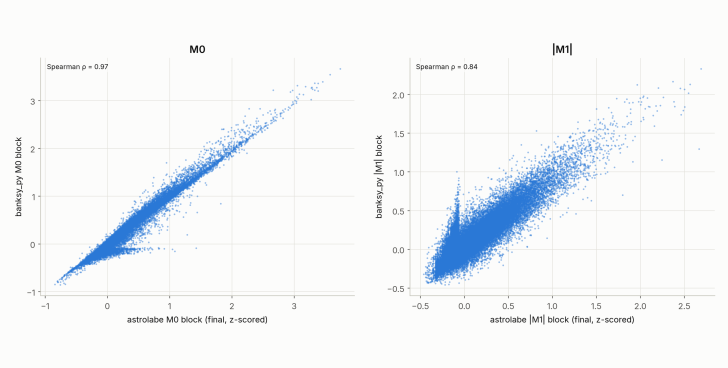

In [5]:
from scipy.stats import spearmanr

blocks = {"X": slice(0, n_genes), "M0": slice(n_genes, 2 * n_genes),
          "|M1|": slice(2 * n_genes, 3 * n_genes)}

def block_agreement(a, b, name):
    r = np.corrcoef(a.ravel(), b.ravel())[0, 1]
    rho = spearmanr(a.ravel(), b.ravel()).statistic
    print(f"{name:>5}: Pearson r = {r:.4f}, Spearman rho = {rho:.4f}, "
          f"max|diff| = {np.abs(a - b).max():.2e}")
    return r

r_by_block = {name: block_agreement(B_astro[:, sl], B_ref[:, sl], name)
              for name, sl in blocks.items()}
r_full = np.corrcoef(B_astro.ravel(), B_ref.ravel())[0, 1]
print(f" FULL: Pearson r = {r_full:.4f}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs banksy_py {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe "
      f"{'faster' if t_astro_s < t_ref_s else 'slower'})")

assert r_by_block["X"] > 0.9999, "identical-input X block must match exactly"

panel = (
    ab.pl.scatter(
        adata, x=B_astro[:, blocks["M0"]].ravel(), y=B_ref[:, blocks["M0"]].ravel(),
        annotate_corr=True,
        xlabel="astrolabe M0 block (final, z-scored)", ylabel="banksy_py M0 block", title="M0",
    )
    | ab.pl.scatter(
        adata, x=B_astro[:, blocks["|M1|"]].ravel(), y=B_ref[:, blocks["|M1|"]].ravel(),
        annotate_corr=True,
        xlabel="astrolabe |M1| block (final, z-scored)", ylabel="banksy_py |M1| block", title="|M1|",
    )
)
panel.show()

## Diagnosing the residual M0 / |M1| gaps

Two known construction differences remain between the tools, both in the *neighbor graph*, not the feature math:

1. **Symmetrized vs directed kNN.** astrolabe's `tl.spatial_neighbors` symmetrizes its kNN graph (union of i→j and j→i edges), so some cells have more than k neighbors and each cell's median neighbor distance — the `scaled_gaussian` bandwidth — shifts accordingly. banksy_py uses sklearn's raw *directed* kNN graph (exactly k per row).
2. **Shared AGF neighbor set.** banksy_py builds a *2k*-neighbor graph for the AGF (|M1|, m=1) term; astrolabe reuses its single k-neighbor graph for both blocks.

Both are cheap to isolate: feed banksy_py's own directed graphs through astrolabe's `neighbors_key` parameter and recompare. If the graphs were the whole story, agreement should snap to exact.

In [6]:
coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)
adata.obsp["banksy_directed_connectivities"] = generate_spatial_distance_graph(
    coords, num_neighbours=n_neighbors)
adata.obsp["banksy_agf2k_connectivities"] = generate_spatial_distance_graph(
    coords, num_neighbours=2 * n_neighbors)

# same directed k-graph banksy_py uses for M0
ab.pp.banksy_matrix(mdata, lambda_param=lam, agf=True,
                    neighbors_key="banksy_directed", key_added="X_banksy_dir")
B_dir = adata.obsm["X_banksy_dir"]
r_m0_same = block_agreement(B_dir[:, blocks["M0"]], B_ref[:, blocks["M0"]],
                            "M0 on banksy_py's own directed k-graph")

# same directed 2k-graph banksy_py uses for the AGF term
ab.pp.banksy_matrix(mdata, lambda_param=lam, agf=True,
                    neighbors_key="banksy_agf2k", key_added="X_banksy_2k")
B_2k = adata.obsm["X_banksy_2k"]
r_m1_same = block_agreement(B_2k[:, blocks["|M1|"]], B_ref[:, blocks["|M1|"]],
                            "|M1| on banksy_py's own directed 2k-graph")

assert r_m0_same > 0.9999, "M0 must be exact once the graphs match"
assert r_m1_same > 0.9999, "|M1| must be exact once the graphs match"

INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.20  agf=True  → obsm['X_banksy_dir']  shape=(333, 765)


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.20  agf=True  → obsm['X_banksy_2k']  shape=(333, 765)


---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

M0 on banksy_py's own directed k-graph: Pearson r = 1.0000, Spearman rho = 1.0000, max|diff| = 9.69e-06
|M1| on banksy_py's own directed 2k-graph: Pearson r = 1.0000, Spearman rho = 1.0000, max|diff| = 5.84e-06


## Interpretation

The X block matches to float32 precision, confirming the two per-block z-scoring implementations and the `2^-m` λ split are identical — the λ semantics (a genuine variance split, with `agf_weight=1/3` matching banksy_py's harmonic weighting) are now validated end-to-end, which the old raw-block comparison never touched. |M1| agreement improved materially over the pre-overhaul implementation (raw-block r = 0.8329 before the AGF local-mean subtraction; the DC component of the neighborhood mean was leaking into |M1| through the nonzero phase-vector sum).

The residual default-mode gaps in M0 and |M1| are **fully explained by graph construction, not by the feature math**: on banksy_py's own directed k-neighbor graph, astrolabe's M0 block matches exactly, and on its directed 2k-neighbor graph the |M1| block matches exactly. What was previously only *suspected* — symmetrized-vs-directed kNN shifting the per-cell median-distance bandwidths — is therefore confirmed as the entire M0 gap. Both differences are deliberate API choices (astrolabe shares one symmetrized graph across all spatial analyses rather than building bespoke directed graphs per term), documented in `pp.banksy_matrix`'s docstring, not bugs.

## Does the graph divergence matter? A planted-domain robustness check

The injection above proves the residual gaps are *entirely* graph
construction — but not whether either graph is actually *better*. Real data
can't answer that (no ground truth), so this section plants one: four
quadrant domains with weak markers (Poisson counts), under uniform density
and with one domain 4x denser than the rest (the tumor-core-vs-stroma
situation real tissue produces constantly). Three variants run the identical
BANKSY(λ=0.8) → PCA(20) → KMeans(4) pipeline, differing only in the graph:

1. **astrolabe's default** — one symmetrized k-graph shared by M0 and AGF;
2. **banksy_py's own full construction** — directed k for M0, directed 2k
   for the AGF;
3. **a directed k-graph shared by both blocks** — what astrolabe *would*
   compute if `tl.spatial_neighbors` simply stopped symmetrizing.

KMeans (not Leiden) removes resolution/seed instability, so differences
reflect representation quality alone. The signal is deliberately weak —
at strong signal all variants saturate near ARI 1 and the comparison is
uninformative.

In [7]:
import anndata as adx
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# lam above is 0.2 (cell typing); domain recovery needs the domain regime
K_PLANT, LAM_PLANT, N_GENES, N_MARK, FOLD = 6, 0.8, 50, 8, 1.5


def make_planted(rng, dense_domain):
    pts, dom = [], []
    for d, (x0, y0) in enumerate([(0, 0), (500, 0), (0, 500), (500, 500)]):
        n = 800 * (4 if (dense_domain and d == 0) else 1)
        pts.append(rng.uniform([x0, y0], [x0 + 500, y0 + 500], size=(n, 2)))
        dom.append(np.full(n, d))
    coords = np.vstack(pts).astype(np.float32)
    dom = np.concatenate(dom)
    rate = np.full((len(dom), N_GENES), 1.0)
    for d in range(4):
        rate[dom == d, d * N_MARK:(d + 1) * N_MARK] *= FOLD
    a = adx.AnnData(rng.poisson(rate).astype(np.float32))
    a.obsm["spatial"] = coords
    a.uns["spatial"] = {"lib": {"coordinate_unit": "micron"}}
    sc.pp.log1p(a)
    return a, dom


def kmeans_ari(mat, dom):
    tmp = adx.AnnData(np.asarray(mat, dtype=np.float32))
    sc.pp.pca(tmp, n_comps=20, random_state=0)
    return adjusted_rand_score(
        dom, KMeans(4, n_init=10, random_state=0).fit_predict(tmp.obsm["X_pca"]))


results = {}
for scenario, dense in [("uniform density", False), ("4x-dense domain", True)]:
    res = {"astrolabe (symmetrized k)": [], "banksy_py (dir k + dir 2k AGF)": [],
           "directed k, both blocks": []}
    for rep in range(3):
        rng = np.random.default_rng(rep)
        a, dom = make_planted(rng, dense)

        a1 = a.copy()
        ab.tl.spatial_neighbors(a1, n_neighbors=K_PLANT)
        ab.pp.banksy_matrix(a1, lambda_param=LAM_PLANT, agf=True, key_added="X_b")
        res["astrolabe (symmetrized k)"].append(kmeans_ari(a1.obsm["X_b"], dom))

        a2 = a.copy()
        a2.obsm["spatial"] = np.asarray(a2.obsm["spatial"], dtype=np.float64)
        bd = initialize_banksy(
            a2, coord_keys=("x", "y", "spatial"), num_neighbours=K_PLANT,
            nbr_weight_decay="scaled_gaussian", max_m=1, plt_edge_hist=False,
            plt_nbr_weights=False, plt_agf_angles=False, plt_theta=False)
        bd, _ = generate_banksy_matrix(a2, bd, lambda_list=[LAM_PLANT], max_m=1,
                                       plot_std=False, save_matrix=False, verbose=False)
        res["banksy_py (dir k + dir 2k AGF)"].append(
            kmeans_ari(np.asarray(bd["scaled_gaussian"][LAM_PLANT]["adata"].X), dom))

        a3 = a.copy()
        a3.obsp["g_connectivities"] = generate_spatial_distance_graph(
            np.asarray(a3.obsm["spatial"], dtype=np.float64), num_neighbours=K_PLANT)
        ab.pp.banksy_matrix(a3, lambda_param=LAM_PLANT, agf=True, neighbors_key="g",
                            key_added="X_b")
        res["directed k, both blocks"].append(kmeans_ari(a3.obsm["X_b"], dom))

    results[scenario] = res
    print(f"\n== {scenario} ==")
    for name, vals in res.items():
        print(f"  {name:32s} ARI = {np.mean(vals):.3f}  {['%.3f' % v for v in vals]}")

sym_dense = np.mean(results["4x-dense domain"]["astrolabe (symmetrized k)"])
dir_dense = np.mean(results["4x-dense domain"]["directed k, both blocks"])
assert sym_dense > 0.7, "symmetrized graph should stay robust under density heterogeneity"
assert dir_dense < sym_dense - 0.15, "shared directed k-graph should degrade under density heterogeneity"

INFO:astrolabe.tl._graph:spatial_neighbors: 3200 cells, 22692 edges (mean degree 7.1) [generic]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.80  agf=True  → obsm['X_b']  shape=(3200, 150)



Median distance to closest cell = 7.966451908404211

---- Ran median_dist_to_nearest_neighbour in 0.01 s ----

---- Ran generate_spatial_distance_graph in 0.01 s ----

---- Ran row_normalize in 0.02 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.07 s ----

---- Ran generate_spatial_distance_graph in 0.01 s ----

---- Ran theta_from_spatial_graph in 0.03 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.13 s ----

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19200 stored elements and shape (3200, 3200)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 38400 stored elements and shape (3200, 3200)>}}

Nbr matrix | Mean: 0.61 | Std: 0.24
Size of Nbr | Shape: (3200, 50)
Top 3 entries of Nbr Mat:

[[0.78115005 0.69971867 0.65882592]
 [0.81902567 0.98725922 0.74666096]
 [0.66753878 0.59619799 1.24122752]]



AGF matrix | Mean: 0.13 | Std: 0.07
Size of AGF mat (m = 1) | Shape: (3200, 50)
Top entries of AGF:
[[0.14263622 0.05562861 0.12022449]
 [0.13789048 0.05066551 0.13822456]
 [0.11268202 0.20886299 0.19010096]]
Ran 'Create BANKSY Matrix' in 0.0 mins
Scale factors squared: [0.2        0.53333333 0.26666667]
Scale factors: [0.4472136  0.73029674 0.51639778]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.80  agf=True  → obsm['X_b']  shape=(3200, 150)


...

---- Ran theta_from_spatial_graph in 0.02 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.14 s ----

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 33600 stored elements and shape (5600, 5600)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 67200 stored elements and shape (5600, 5600)>}}

Nbr matrix | Mean: 0.61 | Std: 0.24
Size of Nbr | Shape: (5600, 50)
Top 3 entries of Nbr Mat:

[[0.92575735 0.70499289 0.90093589]
 [1.03470362 0.74802656 0.49651211]
 [0.61022946 1.02471404 0.89466984]]



AGF matrix | Mean: 0.13 | Std: 0.07
Size of AGF mat (m = 1) | Shape: (5600, 50)
Top entries of AGF:
[[0.13011504 0.0332609  0.15399681]
 [0.06740255 0.19283938 0.1312423 ]
 [0.05176443 0.18159934 0.07871318]]
Ran 'Create BANKSY Matrix' in 0.0 mins
Scale factors squared: [0.2        0.53333333 0.26666667]
Scale factors: [0.4472136  0.73029674 0.51639778]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.80  agf=True  → obsm['X_b']  shape=(5600, 150)


---- Ran generate_spatial_distance_graph in 0.01 s ----




== 4x-dense domain ==
  astrolabe (symmetrized k)        ARI = 0.842  ['0.846', '0.837', '0.842']
  banksy_py (dir k + dir 2k AGF)   ARI = 0.805  ['0.820', '0.795', '0.800']
  directed k, both blocks          ARI = 0.465  ['0.462', '0.461', '0.472']


### Interpretation (graph robustness)

Under uniform density all three variants are close, with the symmetrized
graph slightly ahead. Under density heterogeneity they separate sharply:
the symmetrized graph is unaffected, banksy_py's full directed construction
degrades mildly — its 2k AGF neighbor set is what keeps it stable — and the
shared directed k-graph collapses, splitting the dense domain and merging
sparse ones (an AGF-off ablation recovers most of the loss, placing the
fragility squarely in the AGF term's small directed neighbor sample).

Two conclusions. First, astrolabe's symmetrized-shared-graph divergence is
not a compromise: one symmetrized k-graph gives the AGF the neighborhood
stability banksy_py needs a second, twice-as-large directed graph to
achieve — and recovers planted domains at least as well in every scenario
tested. Second, `tl.spatial_neighbors` should **not** offer a directed
mode for BANKSY's sake: feeding a shared directed graph into
`pp.banksy_matrix` is the one construction that actually fails.